## Object Detection with YOLOv5 (Using Pretrained Weights)
### Problem: Detect objects using pre-trained YOLOv5 model.

In [8]:
# Run the below code to avoid modulenotfound error while loading yolov5 model
import requests
import zipfile
import io
import os

url = "https://github.com/ultralytics/yolov5/archive/refs/heads/master.zip"

response = requests.get(url)

with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
    zip_ref.extractall(".")

print("YOLOv5 downloaded successfully!")

YOLOv5 downloaded successfully!


In [9]:
!pip install -r yolov5-master/requirements.txt

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 24.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/847.1 kB ? eta -:--:--
   --------------------------------------- 847.1/847.1 kB 18.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/52.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/52.6 MB ? eta -:--:--
   - -------------------------------------- 1.8/52.6 MB 4.0 MB/s eta 0:00:13
   - -------------------------------------- 2.4/52.6 MB 3.9 MB/s eta 0:00:13
   -- ------------------------------------- 3.1/52.6 MB 3.7 MB/s eta 0:00:14
   -- ------------------------------------- 3.9/52.6 MB 3.9 MB/s eta 0:00:13
   --- ------------------------------------ 4.7/52.6 MB 3.6 MB/s eta 0:00:14
   --- ------------------------------------ 5.2/52.6 MB 3.5 MB/s eta 0:00:14
   ---- ----------------------------------- 6.0/52.6 MB 3.5 MB/s eta 0:00:14
   ---- ----------------

In [10]:
weights_url = "https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5s.pt"

response = requests.get(weights_url)

with open("yolov5s.pt", "wb") as f:
    f.write(response.content)

print("Pretrained YOLOv5s weights downloaded!")

Pretrained YOLOv5s weights downloaded!


In [11]:

import torch
import matplotlib.pyplot as plt
from PIL import Image

In [12]:
# Load pre-trained YOLOv5 model
# "we have saved the pre-trained weights of the model in yolov5s.pt"
model=torch.hub.load(
    "./yolov5-master",
    "custom",
    path="yolov5s.pt",
    source="local"
)
print("YOLOV5 model loaded successfully")

YOLOv5  2026-8-17 Python-3.12.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1650 with Max-Q Design, 4096MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
YOLOV5 model loaded successfully


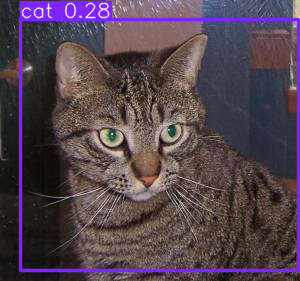

In [13]:
image = Image.open("test.jpg")
results=model(image)
results.show()

In [14]:
detections = results.pandas().xyxy[0]

detections[["name", "confidence"]]

,name,confidence
0,cat,0.275586


## 2. Preprocessing Image for ResNet Input
### Problem: Write a function to preprocess image for pretrained ResNet

In [4]:
# import libraries
import torch
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt



In [5]:
def preprocess_image(image_path):
    # load_image 
    image=Image.open(image_path).convert("RGB")
    # preprocessing required for pretrained resnet
    preprocess=transforms.Compose([
        transforms.Resize(256),
        # resnet expects the image (224,224)
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
          mean=[0.485,0.456,0.406],
          std=[0.229,0.224,0.225]
        )
    ])
    # Apply preprocessing 
    image_tensor = preprocess(image)
    # Add batch dimension
    # resnet expect [batchsize,3,224,224]
    image_tensor = image_tensor.unsqueeze(0)
    return image_tensor

In [6]:
# Load Pretrained ResNet model
weights=models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
model.eval()
print("pretrained ResNet50 loaded successfully")
image_tensor=preprocess_image("test.jpg")
with torch.no_grad():
    output=model(image_tensor)

pretrained ResNet50 loaded successfully


In [2]:
import urllib.request

url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
urllib.request.urlretrieve(url, "imagenet_classes.txt")

('imagenet_classes.txt', <http.client.HTTPMessage at 0x1dadc83c860>)

In [9]:
# To convert raw scores into human-readable(class label)
probabilities=torch.nn.functional.softmax(output[0], dim=0)
# Get top prediction
top_prob,top_catid=torch.max(probabilities,0)
# Load imagenet class labels
with open("imagenet_classes.txt") as f:
    categories=[line.strip() for line in f.readlines()]
print(f"Predicted: {categories[top_catid]} ({top_prob.item()*100:.2f}%)")
# tabby is the cat with stripes, spots or swirls on its fur available in imagenet classes

Predicted: tabby (31.55%)


## 3. CNN for CIFAR-10 Classification
### Problem: Build a CNN model to classify CIFAR-10 images


In [1]:
# importing the libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [2]:
# image preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),
                         (0.5,0.5,0.5))
])

In [3]:
#loading the dataset
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [5]:
#Define the model
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64,128,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4,512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512,10)
        )

    def forward(self,x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CNN()

In [6]:
# Define loss and optimizer
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(
    model.parameters(),
    lr=0.001
)

In [7]:
# Train the model
epochs = 20 
for epoch in range(epochs):
    model.train()
    running_loss=0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs=model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() 
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader):.4f}")

Epoch 1, Loss: 1.4564
Epoch 2, Loss: 1.0470
Epoch 3, Loss: 0.8693
Epoch 4, Loss: 0.7448
Epoch 5, Loss: 0.6551
Epoch 6, Loss: 0.5741
Epoch 7, Loss: 0.5104
Epoch 8, Loss: 0.4527
Epoch 9, Loss: 0.4071
Epoch 10, Loss: 0.3612
Epoch 11, Loss: 0.3293
Epoch 12, Loss: 0.2942
Epoch 13, Loss: 0.2630
Epoch 14, Loss: 0.2439
Epoch 15, Loss: 0.2225
Epoch 16, Loss: 0.2116
Epoch 17, Loss: 0.1981
Epoch 18, Loss: 0.1832
Epoch 19, Loss: 0.1805
Epoch 20, Loss: 0.1681


In [10]:
# Evaluating the model
# Correct is nothing but correct predictions during testing phase, total is nothing but total number of images used for testing
model.eval()
correct = 0
total = 0
# we don't need to calculate gradients as there is no need for updating weights in testing phase
with torch.no_grad():
    for images, labels in test_loader:
        outputs=model(images)
        # After passing the images we will get scores for each class and we will take the maximum score as the predicted class
        # we get both score and label after passing the image, here predicted class label is stored in predicteds
        # here 1 indicates we see values of each row
        _, predicted = torch.max(outputs,1)
        total+=labels.size(0)
        correct+=(predicted==labels).sum().item()
    accuracy=100 * correct/total
    print(f"Test Accuracy: {accuracy:.2f}%")

    


Test Accuracy: 76.19%


## 4. Face Mask Detection – Real-Time Webcam Classifier
### Problem: Build a real-time face mask detector using a trained CNN model and OpenCV.


In [8]:
# To split the images to train and val folder
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split, DataLoader
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim

# Preprocessing
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],
                         [0.5,0.5,0.5])
])

# Load full dataset
full_dataset = ImageFolder("dataset", transform=transform)

# Split sizes (e.g., 80% train, 20% val)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [9]:
class MaskCNN(nn.Module):
    def __init__(self):
        super(MaskCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),  
            # 32x32 input shrinks to 4x4 after pooling
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 2)             
            # 2 classes: mask / without_mask
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MaskCNN().to(device)

In [10]:
# Define loss and optimizer
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(
    model.parameters(),
    lr=0.001
)

In [11]:
# Train the model
epochs = 20 
for epoch in range(epochs):
    model.train()
    running_loss=0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() 
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader):.4f}")

C:\Users\Inst_\anaconda3\envs\aiml1\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1, Loss: 0.3258
Epoch 2, Loss: 0.1815
Epoch 3, Loss: 0.1342
Epoch 4, Loss: 0.1178
Epoch 5, Loss: 0.0918
Epoch 6, Loss: 0.0698
Epoch 7, Loss: 0.0590
Epoch 8, Loss: 0.0414
Epoch 9, Loss: 0.0329
Epoch 10, Loss: 0.0211
Epoch 11, Loss: 0.0228
Epoch 12, Loss: 0.0132
Epoch 13, Loss: 0.0138
Epoch 14, Loss: 0.0173
Epoch 15, Loss: 0.0090
Epoch 16, Loss: 0.0061
Epoch 17, Loss: 0.0026
Epoch 18, Loss: 0.0002
Epoch 19, Loss: 0.0002
Epoch 20, Loss: 0.0001


In [13]:
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Validation Accuracy: {100 * correct / total:.2f}%")

Validation Accuracy: 97.40%


In [14]:
torch.save(model.state_dict(), "face_mask_model.pth")

In [15]:
dataset = ImageFolder("dataset")
print(dataset.classes)        # ['mask', 'without_mask']
print(dataset.class_to_idx)   # {'mask': 0, 'without_mask': 1}

['with_mask', 'without_mask']
{'with_mask': 0, 'without_mask': 1}


In [17]:
import cv2
import torch
from PIL import Image
import torchvision.transforms as transforms

#  Load trained CNN model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MaskCNN().to(device)
model.load_state_dict(torch.load("face_mask_model.pth", map_location=device))
model.eval()

#  Preprocessing (same as training)
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

# Load Haar cascade face detector (comes with OpenCV)
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

#  Start webcam
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.3, 5)

    for (x, y, w, h) in faces:
        # Crop face
        face_img = frame[y:y+h, x:x+w]
        if face_img.size == 0:
            continue

        # Convert to PIL and preprocess
        face_pil = Image.fromarray(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB))
        face_tensor = transform(face_pil).unsqueeze(0).to(device)

        # Predict with CNN
        with torch.no_grad():
            outputs = model(face_tensor)
            _, predicted = torch.max(outputs, 1)

        # Map prediction to label
        label = "Mask" if predicted.item() == 0 else "No Mask"
        color = (0, 255, 0) if label == "Mask" else (0, 0, 255)

        # Draw bounding box + label
        cv2.rectangle(frame, (x, y), (x+w, y+h), color, 2)
        cv2.putText(frame, label, (x, y-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)

    cv2.imshow("Face Mask Detection", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


## 5.Custom Transfer Learning with Frozen + Trainable Layers
### Problem: Load a pretrained MobileNetV2 model, freeze base layers, add custom classifier, and fine-tune the top few layers.


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models



In [2]:
# Dataset preparation
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                             download=True, transform=transform_train)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                            download=True, transform=transform_test)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)



In [3]:
# Load pretrained MobileNetV2
mobilenet = models.mobilenet_v2(pretrained=True)

# Freeze all base layers
for param in mobilenet.features.parameters():
    param.requires_grad = False

C:\Users\Inst_\anaconda3\envs\aiml1\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Inst_\anaconda3\envs\aiml1\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [4]:
# Replace classifier
num_features = mobilenet.classifier[1].in_features
mobilenet.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(num_features, 10)   # CIFAR-10 has 10 classes
)

In [6]:
# Fine-tune top few layers
# Unfreeze last convolutional block
for param in mobilenet.features[-1].parameters():
    param.requires_grad = True

In [7]:
# Training setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mobilenet = mobilenet.to(device)
# Define loss criterion
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, mobilenet.parameters()), lr=0.001)

In [8]:
# Training Loop
epochs = 10
for epoch in range(epochs):
    mobilenet.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = mobilenet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader):.4f}")

Epoch 1, Loss: 1.2237
Epoch 2, Loss: 1.1167
Epoch 3, Loss: 1.0638
Epoch 4, Loss: 1.0513
Epoch 5, Loss: 1.0164
Epoch 6, Loss: 1.0069
Epoch 7, Loss: 0.9873
Epoch 8, Loss: 0.9638
Epoch 9, Loss: 0.9614
Epoch 10, Loss: 0.9506


In [16]:
# Evaluation
mobilenet.eval()
correct, total = 0, 0
with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = mobilenet(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f"Accuracy: {100 * correct / total:.2f}%")

Accuracy: 78.65%
